### Getting_Started 

This notebook gives an explainer of the functionalities of the repository, how to call different functions and parameters that can be changed.

In [1]:
# --- 1. Imports, environment, and source-file checks ---

import gc
import os
import time

# Must be set before importing JAX, WDM, FEW, or anything that may import JAX.
os.environ["JAX_PLATFORMS"] = "cpu"

import jax
import jax.numpy as jnp
import WDM
import numpy as np
import matplotlib.pyplot as plt

try:
    import psutil
except ImportError:
    psutil = None

from WDM_LISAresponse.code.lisa_response.response_with_plan import (
    one_arm_response_td,
)
from WDM_LISAresponse.code.lisa_response.TDI_with_one_arm_plan import (
    gen2_michelson_td,
    precompute_gen2_michelson_wdm_geometry,
    precompute_gen2_michelson_wdm_waveform,
    gen2_michelson_wdm_from_waveform_precomputed,
)
from WDM_LISAresponse.code.lisa_response.waveforms import (
    generate_windowed_padded_waveform,
)
from WDM_LISAresponse.code.utils.utils import (
    apply_wdm_cut,
    compute_wdm_cut_info,
    wdm_mismatch,
)

from lisaorbits.file import read_orbit_file
from lisaorbits import InterpolatedOrbits
from few.waveform import GenerateEMRIWaveform
from few.utils.constants import YRSID_SI


_process = psutil.Process(os.getpid()) if psutil is not None else None


def rss_gib():
    """Current process resident memory, including JAX/XLA CPU buffers."""
    if _process is None:
        return np.nan
    return _process.memory_info().rss / 1024**3


def block_result(result):
    """Synchronize JAX arrays before stopping a benchmark timer."""
    if isinstance(result, dict):
        for value in result.values():
            block_result(value)
        return

    if isinstance(result, (tuple, list)):
        for value in result:
            block_result(value)
        return

    if hasattr(result, "block_until_ready"):
        result.block_until_ready()


def median_runtime(callable_, repeats=3):
    """Warm once, then return the median synchronized runtime."""
    result = callable_()
    block_result(result)

    timings = []

    for _ in range(repeats):
        started = time.perf_counter()

        result = callable_()
        block_result(result)

        timings.append(time.perf_counter() - started)

    return float(np.median(timings))


print("Requested JAX platforms:", os.environ["JAX_PLATFORMS"])
print("JAX backend:", jax.default_backend())
print("JAX devices:", jax.devices())

assert jax.default_backend() == "cpu", (
    "JAX was not initialized on CPU. Restart the kernel and run this "
    "cell before any JAX-related import."
)
assert all(device.platform == "cpu" for device in jax.devices())

Requested JAX platforms: cpu
JAX backend: cpu
JAX devices: [CpuDevice(id=0)]


Setup of the lisaorbits functions and the EMRI waveform generation functions

In [2]:
#very expensive to build td_gen 

td_gen = GenerateEMRIWaveform(
    "FastKerrEccentricEquatorialFlux",
    sum_kwargs=dict(pad_output=True, odd_len=True),
    return_list=True
)

orbit_data = read_orbit_file('esa-trailing-orbits.h5')

orbit_times = orbit_data.t0 + orbit_data.dt * np.arange(orbit_data.size)
t_start = orbit_data.t0

orbits_trailing = InterpolatedOrbits(orbit_times, 
                                     orbit_data.positions, 
                                     orbit_data.velocities)

Parameters for the waveform generation

In [3]:

#window function parameters 
alpha = 0.005
tukey_factor = 4

#data series parameters
t0 = t_start + 1.0*YRSID_SI
N = 3200000
dt = 10
Nf = 100
#T_obs = 1 #can use either N or T_obs 

#orbit parameters for EMRI
m1 = 1e6
m2 = 10.0
a = 0.9
p0 = 8.5
e0 = 0.3
x0 = 1.0

#sky position parameters
dist = 1.0
theta = np.pi / 2
phi = 0
qK = np.pi / 3
phiK = np.pi / 3

#accuracy of interpolation
eps = 1e-2

# initial phases
Phi_phi0 = np.pi / 3
Phi_theta0 = 0.0
Phi_r0 = np.pi / 3

### Numerical and benchmark settings

The WDM calculation uses the staged API:

- **A0:** WDM grid, one-arm geometry, one-arm shift plan, recursive TDI delays, and the prepared 42-job TDI plan;
- **A1:** transform the actual waveform and apply the prepared six-link one-arm plan;
- **B:** apply the prepared TDI plan and accumulate the second-generation Michelson \(X,Y,Z\) channels.

For long laptop runs, grouped TDI execution is the production path. The fully materialized 42-job route is retained only as an optional numerical and scaling reference because its temporary output exceeds \(1\) GiB at approximately one-year duration.


In [4]:
q_wdm = 4
L_trunc_value = 25
num_int_points = 20

# Long-duration notebook controls.
# Full TD references and the materialized 42-job TDI route are expensive
# at N~3.2e6.
RUN_TD_REFERENCE = False
RUN_MATERIALIZED_REFERENCE = False
BENCHMARK_REPEATS = 9

# One-arm validation and comparison controls.
RUN_ONE_ARM_VALIDATION = True
RUN_ONE_ARM_BENCHMARK = True
ONE_ARM_BENCHMARK_REPEATS = 15

# Device output location and one-arm execution strategy are independent.
# "materialized" is the faster CPU route. "fused_low_memory" retains the
# Commit-3B halo-fused route as an optional lower-memory implementation.
ONE_ARM_EXECUTION_MODE = "materialized"

fast_shift_kwargs = {
    "assembly_backend": "lagfirst_chunked_lagblock",
    "assembly_precision": "complex64",
    "row_chunk_size": 4096,
    "lag_block_size": 32,
    "tl_tp_mode": "interp",
    "tl_tp_interp_points": 32,
    "tl_tp_interp_kind": "linear",
    "use_jax": True,
}

faithful_shift_kwargs = {
    "assembly_backend": "lagfirst_chunked",
    "assembly_precision": "complex128",
    "row_chunk_size": 128,
    "tl_tp_mode": "exact",
    "use_jax": True,
}

legacy_shift_kwargs = {
    "assembly_backend": "legacy",
    "assembly_precision": "complex128",
    "tl_tp_mode": "exact",
    "use_jax": True,
}

# Choose the configuration during A0. Do not override it in A1.
shift_kwargs = fast_shift_kwargs

print("JAX backend:", jax.default_backend())
print("JAX devices:", jax.devices())
print("One-arm execution mode:", ONE_ARM_EXECUTION_MODE)
print(f"Process RSS before waveform generation: {rss_gib():.2f} GiB")


JAX backend: cpu
JAX devices: [CpuDevice(id=0)]
One-arm execution mode: materialized
Process RSS before waveform generation: 6.19 GiB


Waveform generation + plotting 

Generated padded waveform length: 3264000
WDM Nt x Nf = 32640 x 100
Tail right padding: 0


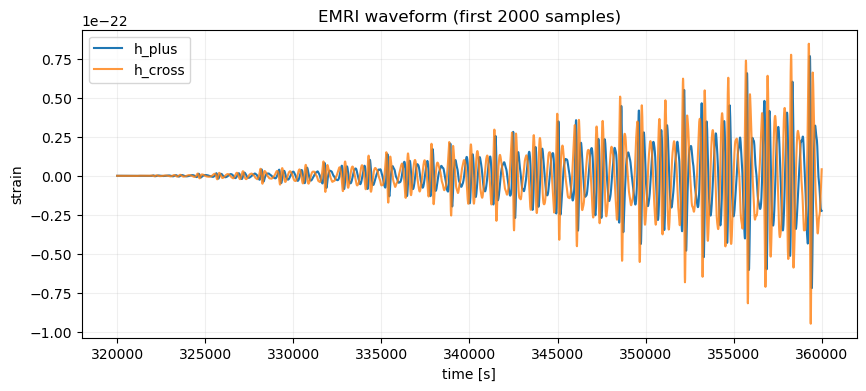

Process RSS after waveform generation: 6.47 GiB


In [5]:
model_kwargs = {
    "td_gen": td_gen,
    "m1": m1,
    "m2": m2,
    "a": a,
    "p0": p0,
    "e0": e0,
    "x0": x0,
    "dist": dist,
    "theta": theta,
    "phi": phi,
    "qK": qK,
    "phiK": phiK,
    "Phi_phi0": Phi_phi0,
    "Phi_theta0": Phi_theta0,
    "Phi_r0": Phi_r0,
    "eps": eps,
}

window_kwargs = {
    "alpha": alpha,
    "tukey_factor": tukey_factor,
}

times_pad, hplus_td, hcross_td, pad_info = generate_windowed_padded_waveform(
    waveform_model="emri",
    t0=t0,
    dt=dt,
    N= N,
    model_kwargs=model_kwargs,
    window_function="tukey",
    window_kwargs=window_kwargs,
    wdm_Nf=Nf,
    return_padding_info=True,
 )

print(f"Generated padded waveform length: {len(times_pad)}")
print(f"WDM Nt x Nf = {pad_info['wdm_Nt']} x {Nf}")
print(f"Tail right padding: {pad_info['wdm_tail_pad_right']}")

plotting_times = times_pad - times_pad[0]
plt_left_lim = int(0.5 * (len(times_pad) - N))

plt.figure(figsize=(10, 4))
plt.plot(plotting_times[plt_left_lim:plt_left_lim+4000], hplus_td[plt_left_lim:plt_left_lim+4000], label="h_plus")
plt.plot(plotting_times[plt_left_lim:plt_left_lim+4000], hcross_td[plt_left_lim:plt_left_lim+4000], label="h_cross", alpha=0.8)
plt.title("EMRI waveform (first 2000 samples)")
plt.xlabel("time [s]")
plt.ylabel("strain")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print(f"Process RSS after waveform generation: {rss_gib():.2f} GiB")



### Time-domain one-arm reference


In [6]:
if RUN_TD_REFERENCE:
    t_td0 = time.perf_counter()

    dl_12_td = one_arm_response_td(
        times_pad,
        1,
        2,
        orbits_trailing,
        theta,
        phi,
        hplus_td,
        hcross_td,
        num_int_points=num_int_points,
    )

    td_one_arm_time = time.perf_counter() - t_td0

    print(f"TD one-arm runtime: {td_one_arm_time:.3f} s")
    print(f"TD one-arm shape: {dl_12_td.shape}")
else:
    dl_12_td = None
    print("TD one-arm reference skipped. Set RUN_TD_REFERENCE=True to run it.")


TD one-arm reference skipped. Set RUN_TD_REFERENCE=True to run it.


In [7]:
# --------------------
# A0: static/grid/geometry/operator setup
# --------------------
t_a0 = time.perf_counter()

geom_precomp = precompute_gen2_michelson_wdm_geometry(
    times_pad,
    theta,
    phi,
    orbits_trailing,
    Nf=Nf,
    L_trunc=L_trunc_value,
    q=q_wdm,
    d=4,
    A_frac=0.25,
    calc_m0=True,
    variable_shift_kwargs=shift_kwargs,
)

a0_time = time.perf_counter() - t_a0
rss_after_a0 = rss_gib()

one_arm_shift_plan = geom_precomp["one_arm_plan"].shift_plan
tdi_plan = geom_precomp["tdi_plan"]

assert (
    one_arm_shift_plan.resolved_assembly_backend
    == "lagfirst_chunked_lagblock"
), one_arm_shift_plan.resolved_assembly_backend

assert (
    tdi_plan.shift_plan.resolved_assembly_backend
    == "lagfirst_chunked_lagblock"
), tdi_plan.shift_plan.resolved_assembly_backend

assert hasattr(
    one_arm_shift_plan,
    "apply_weighted_sources_device",
), (
    "The loaded VariableShiftBatchPlan does not contain the commit-3B "
    "weighted-source method. Restart the kernel after replacing the source files."
)

# --------------------
# A1: actual waveform -> six one-arm WDM links
# --------------------
# Keep the six shifted links on-device while selecting the faster
# device-materialized one-arm implementation explicitly.
t_a1 = time.perf_counter()

wave_precomp = precompute_gen2_michelson_wdm_waveform(
    geom_precomp,
    hplus_td,
    hcross_td,
    return_device_links=True,
    one_arm_execution_mode=ONE_ARM_EXECUTION_MODE,
)

# JAX execution is asynchronous. Synchronize all links before stopping
# the A1 timer, otherwise this records dispatch rather than runtime.
block_result(tuple(wave_precomp["link_w"].values()))

a1_time = time.perf_counter() - t_a1
rss_after_a1 = rss_gib()

assert wave_precomp["one_arm_plan"] is geom_precomp["one_arm_plan"]
assert wave_precomp["tdi_plan"] is geom_precomp["tdi_plan"]
assert wave_precomp["one_arm_execution_mode"] == ONE_ARM_EXECUTION_MODE

wdm_response = wave_precomp["wdm"]
link_w = wave_precomp["link_w"]
w_12_wdm = link_w[(1, 2)]

for link_array in link_w.values():
    assert isinstance(link_array, jax.Array)

a0_accounted = (
    geom_precomp["wdm_grid_build_s"]
    + geom_precomp["one_arm_plan_build_s"]
    + geom_precomp["tdi_delay_build_s"]
    + geom_precomp["tdi_plan_build_s"]
)

waveform_context_s = float(wave_precomp["waveform_context_build_s"])
synchronized_link_stage_s = max(0.0, a1_time - waveform_context_s)

print(f"A0 setup runtime:                    {a0_time:.3f} s")
print("A0 breakdown:")
print(f"  WDM grid construction:             {geom_precomp['wdm_grid_build_s']:.3f} s")
print(f"  one-arm plan construction:         {geom_precomp['one_arm_plan_build_s']:.3f} s")
print(f"  recursive TDI delay fields:        {geom_precomp['tdi_delay_build_s']:.3f} s")
print(f"  prepared 42-job TDI plan:          {geom_precomp['tdi_plan_build_s']:.3f} s")
print(f"  TDI delays loaded from cache:      {geom_precomp['tdi_delays_from_cache']}")
print(f"  other A0 overhead:                 {a0_time - a0_accounted:.3f} s")
print()
print(f"One-arm backend:                     {one_arm_shift_plan.resolved_assembly_backend}")
print(f"One-arm execution mode:              {wave_precomp['one_arm_execution_mode']}")
print(f"TDI backend:                         {tdi_plan.shift_plan.resolved_assembly_backend}")
print(f"One-arm persistent kernel memory:    {one_arm_shift_plan.kernel_memory_bytes / 1024**2:.2f} MiB")
print(f"TDI persistent kernel memory:        {tdi_plan.kernel_memory_bytes / 1024**2:.2f} MiB")
print(f"Process RSS after A0:                 {rss_after_a0:.2f} GiB")
print()
print(f"A1 synchronized waveform + 6 links:  {a1_time:.3f} s")
print(f"  waveform context / two DWTs:       {waveform_context_s:.3f} s")
print(f"  one-arm link stage + wrapper:       {synchronized_link_stage_s:.3f} s")
print(f"Process RSS after A1:                 {rss_after_a1:.2f} GiB")
print(f"One-arm coefficient shape:           {w_12_wdm.shape}")
print(f"One-arm coefficient dtype:           {w_12_wdm.dtype}")
print("One-arm links returned on device:    yes")
print("One-arm plan reused by A1:           yes")
print("TDI plan reused by A1:               yes")


A0 setup runtime:                    13.175 s
A0 breakdown:
  WDM grid construction:             2.992 s
  one-arm plan construction:         1.534 s
  recursive TDI delay fields:        5.465 s
  prepared 42-job TDI plan:          3.184 s
  TDI delays loaded from cache:      False
  other A0 overhead:                 0.000 s

One-arm backend:                     lagfirst_chunked_lagblock
One-arm execution mode:              materialized
TDI backend:                         lagfirst_chunked_lagblock
One-arm persistent kernel memory:    329.71 MiB
TDI persistent kernel memory:        2158.54 MiB
Process RSS after A0:                 9.85 GiB

A1 synchronized waveform + 6 links:  1.643 s
  waveform context / two DWTs:       0.638 s
  one-arm link stage + wrapper:       1.005 s
Process RSS after A1:                 10.60 GiB
One-arm coefficient shape:           (32640, 100)
One-arm coefficient dtype:           complex64
One-arm links returned on device:    yes
One-arm plan reused by A1:  


### Second-generation Michelson TDI


In [8]:
if RUN_TD_REFERENCE:
    t_tdi_td0 = time.perf_counter()

    X_td, Y_td, Z_td = gen2_michelson_td(
        times_pad,
        hplus_td,
        hcross_td,
        theta,
        phi,
        orbits_trailing,
        order=7,
        num_int_points=num_int_points,
    )

    td_tdi_time = time.perf_counter() - t_tdi_td0

    print(f"TD TDI runtime: {td_tdi_time:.3f} s")
    print(f"TD X/Y/Z shapes: {X_td.shape}, {Y_td.shape}, {Z_td.shape}")
else:
    X_td = Y_td = Z_td = None
    print("TD TDI reference skipped. Set RUN_TD_REFERENCE=True to run it.")


TD TDI reference skipped. Set RUN_TD_REFERENCE=True to run it.


In [9]:
# --------------------
# B: six prepared links -> X, Y, Z
# --------------------
# The prepared-plan path now uses grouped indexed accumulation.
# The first call may include JAX compilation for this shape.
t_b_cold = time.perf_counter()
X_wdm_cold, Y_wdm_cold, Z_wdm_cold = gen2_michelson_wdm_from_waveform_precomputed(
    wave_precomp,
    tdi_assembly_mode="prepared_plan",
)
block_result((X_wdm_cold, Y_wdm_cold, Z_wdm_cold))
b_cold_time = time.perf_counter() - t_b_cold

# Steady-state application of the already prepared and compiled plan.
t_b_warm = time.perf_counter()
X_wdm, Y_wdm, Z_wdm = gen2_michelson_wdm_from_waveform_precomputed(
    wave_precomp,
    tdi_assembly_mode="prepared_plan",
)
block_result((X_wdm, Y_wdm, Z_wdm))
b_warm_time = time.perf_counter() - t_b_warm
rss_after_grouped_b = rss_gib()

np.testing.assert_allclose(X_wdm, X_wdm_cold, rtol=1e-7, atol=1e-7)
np.testing.assert_allclose(Y_wdm, Y_wdm_cold, rtol=1e-7, atol=1e-7)
np.testing.assert_allclose(Z_wdm, Z_wdm_cold, rtol=1e-7, atol=1e-7)

print(f"B TDI cold runtime:                  {b_cold_time:.3f} s")
print(f"B TDI warm runtime:                  {b_warm_time:.3f} s")
print(f"Process RSS after grouped B:          {rss_after_grouped_b:.2f} GiB")
print(f"WDM X/Y/Z coefficient shapes:        {X_wdm.shape}, {Y_wdm.shape}, {Z_wdm.shape}")

print("\nStaged WDM timing:")
print(f"A0 static setup:                     {a0_time:.3f} s")
print(f"A1 waveform + 6 links:               {a1_time:.3f} s")
print(f"B grouped TDI warm application:      {b_warm_time:.3f} s")
print(f"A1 + B repeated cost:                {a1_time + b_warm_time:.3f} s")


B TDI cold runtime:                  6.190 s
B TDI warm runtime:                  5.255 s
Process RSS after grouped B:          11.80 GiB
WDM X/Y/Z coefficient shapes:        (32640, 100), (32640, 100), (32640, 100)

Staged WDM timing:
A0 static setup:                     13.175 s
A1 waveform + 6 links:               1.643 s
B grouped TDI warm application:      5.255 s
A1 + B repeated cost:                6.898 s



### Comparison of the TD and WDM methods in WDM space

The TD references are transformed with the **same WDM object** used by the staged response calculation. Boundary and \(m=0\) cuts are applied through the utility helpers.


In [10]:
if RUN_TD_REFERENCE:
    # The waveform generator has already padded times_pad to a valid WDM length,
    # so use the exact same transform object as the response pipeline.
    if len(dl_12_td) != int(wdm_response.N):
        raise ValueError(
            f"TD response length {len(dl_12_td)} does not match WDM N={wdm_response.N}."
        )

    w_12_td = wdm_response.dwt(dl_12_td)

    cut_info_one_arm = compute_wdm_cut_info(
        original_length=N,
        Nf=Nf,
        dt=dt,
        alpha=alpha,
        tukey_factor=tukey_factor,
        window_pad_left=pad_info["window_pad_left"],
        window_pad_right=pad_info["window_pad_right"],
        wdm_dT=wdm_response.dT,
        wdm_Nt=wdm_response.Nt,
        include_wdm_tail_padding=True,
        include_taper_margin=True,
        drop_m0=True,
    )

    f_max = wdm_response.Nf * wdm_response.dF

    fig, ax = WDM.plotting.time_frequency_plot(
        wdm_response, w_12_td, part="real", scale="linear"
    )
    ax.set_ylim(0, f_max)
    plt.show()

    fig, ax = WDM.plotting.time_frequency_plot(
        wdm_response, w_12_wdm, part="real", scale="linear"
    )
    ax.set_ylim(0, f_max)
    plt.show()

    fig, ax = WDM.plotting.time_frequency_plot(
        wdm_response, w_12_td - w_12_wdm, part="abs", scale="linear"
    )
    ax.set_ylim(0, f_max)
    plt.show()

    td_cut = apply_wdm_cut(w_12_td, cut_info_one_arm)
    wdm_cut = apply_wdm_cut(np.asarray(w_12_wdm).real, cut_info_one_arm)

    ov_wdm, mm_wdm = wdm_mismatch(td_cut, wdm_cut)
    print(f"One-arm WDM-domain overlap={ov_wdm:.9f}, mismatch={mm_wdm:.3e}")
    print(
        "Applied cuts:",
        f"left={cut_info_one_arm['left_cut']},",
        f"right={cut_info_one_arm['right_cut']},",
        f"drop_m0={cut_info_one_arm['trim_m0']}",
    )
else:
    cut_info_one_arm = None
    print("One-arm TD-vs-WDM comparison skipped.")


One-arm TD-vs-WDM comparison skipped.


In [11]:
if RUN_TD_REFERENCE:
    # TDI response plot in the time domain (TD baseline)
    plt.figure(figsize=(10, 5))
    plt.plot(
        plotting_times[plt_left_lim:plt_left_lim + 4000],
        X_td[plt_left_lim:plt_left_lim + 4000],
        label="X_td",
    )
    plt.plot(
        plotting_times[plt_left_lim:plt_left_lim + 4000],
        Y_td[plt_left_lim:plt_left_lim + 4000],
        label="Y_td",
    )
    plt.plot(
        plotting_times[plt_left_lim:plt_left_lim + 4000],
        Z_td[plt_left_lim:plt_left_lim + 4000],
        label="Z_td",
    )
    plt.title("Gen2 Michelson TDI responses")
    plt.xlabel("time [s]")
    plt.ylabel("response")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

    if not (len(X_td) == len(Y_td) == len(Z_td) == int(wdm_response.N)):
        raise ValueError("TD TDI arrays do not match the staged WDM grid length.")

    X_td_w = wdm_response.dwt(X_td)
    Y_td_w = wdm_response.dwt(Y_td)
    Z_td_w = wdm_response.dwt(Z_td)

    cut_info_tdi = cut_info_one_arm

    X_td_cut = apply_wdm_cut(X_td_w, cut_info_tdi)
    Y_td_cut = apply_wdm_cut(Y_td_w, cut_info_tdi)
    Z_td_cut = apply_wdm_cut(Z_td_w, cut_info_tdi)

    X_wdm_cut = apply_wdm_cut(np.asarray(X_wdm).real, cut_info_tdi)
    Y_wdm_cut = apply_wdm_cut(np.asarray(Y_wdm).real, cut_info_tdi)
    Z_wdm_cut = apply_wdm_cut(np.asarray(Z_wdm).real, cut_info_tdi)

    X_ov, X_mm = wdm_mismatch(X_td_cut, X_wdm_cut)
    Y_ov, Y_mm = wdm_mismatch(Y_td_cut, Y_wdm_cut)
    Z_ov, Z_mm = wdm_mismatch(Z_td_cut, Z_wdm_cut)

    print("TDI TD-vs-WDM mismatch in WDM domain:")
    print(f"X: overlap={X_ov:.9f}, mismatch={X_mm:.3e}")
    print(f"Y: overlap={Y_ov:.9f}, mismatch={Y_mm:.3e}")
    print(f"Z: overlap={Z_ov:.9f}, mismatch={Z_mm:.3e}")

    plt.figure(figsize=(10, 4))
    plt.plot(np.abs(X_td_cut - X_wdm_cut).mean(axis=1), label="X")
    plt.plot(np.abs(Y_td_cut - Y_wdm_cut).mean(axis=1), label="Y")
    plt.plot(np.abs(Z_td_cut - Z_wdm_cut).mean(axis=1), label="Z")
    plt.title("Mean absolute coefficient difference per retained time row")
    plt.xlabel("retained WDM time-row index")
    plt.ylabel("mean |delta coefficient|")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()
else:
    print("TDI TD-vs-WDM comparison skipped.")


TDI TD-vs-WDM comparison skipped.


### One-arm execution-mode validation

The staged A1 production path now uses the device-materialized implementation
while retaining device-resident outputs. The halo-fused implementation remains
available explicitly as `fused_low_memory`.

The following cells verify:

1. the production device-materialized result against the host materialized
   reference;
2. the optional halo-fused result against the production materialized result;
3. the runtime trade-off between the two complete one-arm routes.


In [12]:
if RUN_ONE_ARM_VALIDATION:
    # ------------------------------------------------------------
    # 1. Production device-materialized route versus host reference
    # ------------------------------------------------------------
    wave_precomp_host = precompute_gen2_michelson_wdm_waveform(
        geom_precomp,
        hplus_td,
        hcross_td,
        return_device_links=False,
    )

    materialized_links = wave_precomp["link_w"]
    host_links = wave_precomp_host["link_w"]

    block_result(materialized_links)

    materialized_maximum_absolute = 0.0
    materialized_maximum_relative_l2 = 0.0

    for link in host_links:
        host_value = np.asarray(host_links[link])
        materialized_array = materialized_links[link]
        materialized_value = np.asarray(materialized_array)

        difference = materialized_value - host_value
        host_norm = np.linalg.norm(host_value)
        relative_l2 = (
            float(np.linalg.norm(difference) / host_norm)
            if host_norm > 0
            else float(np.linalg.norm(difference))
        )

        materialized_maximum_absolute = max(
            materialized_maximum_absolute,
            float(np.max(np.abs(difference))),
        )
        materialized_maximum_relative_l2 = max(
            materialized_maximum_relative_l2,
            relative_l2,
        )

        np.testing.assert_allclose(
            materialized_value,
            host_value,
            rtol=2e-6,
            atol=2e-7,
        )
        assert isinstance(materialized_array, jax.Array)

    del wave_precomp_host, host_links
    gc.collect()

    # ------------------------------------------------------------
    # 2. Optional fused-low-memory route versus production route
    # ------------------------------------------------------------
    wave_precomp_fused = precompute_gen2_michelson_wdm_waveform(
        geom_precomp,
        hplus_td,
        hcross_td,
        return_device_links=True,
        one_arm_execution_mode="fused_low_memory",
    )

    fused_links = wave_precomp_fused["link_w"]
    block_result(fused_links)

    fused_maximum_absolute = 0.0
    fused_maximum_relative_l2 = 0.0

    for link in materialized_links:
        materialized_value = np.asarray(materialized_links[link])
        fused_array = fused_links[link]
        fused_value = np.asarray(fused_array)

        difference = fused_value - materialized_value
        materialized_norm = np.linalg.norm(materialized_value)
        relative_l2 = (
            float(np.linalg.norm(difference) / materialized_norm)
            if materialized_norm > 0
            else float(np.linalg.norm(difference))
        )

        fused_maximum_absolute = max(
            fused_maximum_absolute,
            float(np.max(np.abs(difference))),
        )
        fused_maximum_relative_l2 = max(
            fused_maximum_relative_l2,
            relative_l2,
        )

        np.testing.assert_allclose(
            fused_value,
            materialized_value,
            rtol=2e-6,
            atol=2e-7,
        )
        assert isinstance(fused_array, jax.Array)

    print("One-arm execution-mode validation:")
    print("  production mode:                    materialized")
    print(
        "  materialized vs host max abs:       "
        f"{materialized_maximum_absolute:.6e}"
    )
    print(
        "  materialized vs host max rel L2:    "
        f"{materialized_maximum_relative_l2:.6e}"
    )
    print(
        "  fused vs materialized max abs:      "
        f"{fused_maximum_absolute:.6e}"
    )
    print(
        "  fused vs materialized max rel L2:   "
        f"{fused_maximum_relative_l2:.6e}"
    )
    print(
        "  device link dtype:                  "
        f"{materialized_links[(1, 2)].dtype}"
    )
    print("  both device routes match their references")

    del wave_precomp_fused, fused_links
    gc.collect()
else:
    print("One-arm validation skipped.")


One-arm execution-mode validation:
  production mode:                    materialized
  materialized vs host max abs:       1.084202e-18
  materialized vs host max rel L2:    8.642682e-08
  fused vs materialized max abs:      1.301043e-18
  fused vs materialized max rel L2:   9.459003e-08
  device link dtype:                  complex64
  both device routes match their references


In [13]:
# --------------------
# Same-backend complete one-arm benchmark
# --------------------
# Both routes use lagfirst_chunked_lagblock. The two DWTs are performed once,
# outside the timed loop.
if RUN_ONE_ARM_BENCHMARK:
    from WDM_LISAresponse.code.lisa_response.response_with_plan import (
        _build_wdm_dT_context_from_wdm,
    )

    one_arm_plan = geom_precomp["one_arm_plan"]

    assert (
        one_arm_plan.shift_plan.resolved_assembly_backend
        == "lagfirst_chunked_lagblock"
    )
    assert hasattr(one_arm_plan, "apply_batch_device_materialized")
    assert hasattr(one_arm_plan, "apply_batch_device")

    wave_context_one_arm = _build_wdm_dT_context_from_wdm(
        geom_precomp["times"],
        hplus_td,
        hcross_td,
        geom_precomp["wdm"],
        m_offset=0.0,
    )

    w_t_plus = wave_context_one_arm["w_t_plus"]
    w_t_cross = wave_context_one_arm["w_t_cross"]

    def run_materialized():
        """Complete fast CPU route used by the staged production pipeline."""
        return one_arm_plan.apply_batch_device_materialized(
            w_t_plus,
            w_t_cross,
        )

    def run_fused_low_memory():
        """Complete halo-fused route retained for lower transient memory."""
        return one_arm_plan.apply_batch_device(
            w_t_plus,
            w_t_cross,
        )

    # Compile, populate caches, and verify both complete routes before timing.
    materialized_warmup = run_materialized()
    block_result(materialized_warmup)

    fused_warmup = run_fused_low_memory()
    block_result(fused_warmup)

    np.testing.assert_allclose(
        np.asarray(fused_warmup),
        np.asarray(materialized_warmup),
        rtol=2e-6,
        atol=2e-7,
    )

    del materialized_warmup, fused_warmup

    timings = {
        "materialized": [],
        "fused_low_memory": [],
    }

    # Alternate execution order to reduce systematic first/second-run bias.
    for repeat_index in range(ONE_ARM_BENCHMARK_REPEATS):
        order = (
            ("fused_low_memory", "materialized")
            if repeat_index % 2 == 0
            else ("materialized", "fused_low_memory")
        )

        for route in order:
            started = time.perf_counter()

            result = (
                run_materialized()
                if route == "materialized"
                else run_fused_low_memory()
            )
            block_result(result)

            timings[route].append(
                time.perf_counter() - started
            )
            del result

    materialized_median = float(
        np.median(timings["materialized"])
    )
    fused_median = float(
        np.median(timings["fused_low_memory"])
    )

    print(
        f"Lag-blocked complete one-arm benchmark "
        f"({ONE_ARM_BENCHMARK_REPEATS} runs per route):"
    )
    print()
    print("  Device-materialized production route:")
    print(f"    median:  {materialized_median:.3f} s")
    print(f"    minimum: {min(timings['materialized']):.3f} s")
    print(f"    maximum: {max(timings['materialized']):.3f} s")
    print(
        "    all:    ",
        [round(value, 3) for value in timings["materialized"]],
    )
    print()
    print("  Halo-fused low-memory route:")
    print(f"    median:  {fused_median:.3f} s")
    print(f"    minimum: {min(timings['fused_low_memory']):.3f} s")
    print(f"    maximum: {max(timings['fused_low_memory']):.3f} s")
    print(
        "    all:    ",
        [round(value, 3) for value in timings["fused_low_memory"]],
    )
    print()
    print(
        f"  materialized/fused speed ratio: "
        f"{materialized_median / fused_median:.3f}x"
    )
    print(
        f"  fused runtime change:            "
        f"{100.0 * (fused_median / materialized_median - 1.0):+.1f}%"
    )

    gc.collect()
else:
    print("One-arm benchmark skipped.")


Lag-blocked complete one-arm benchmark (15 runs per route):

  Device-materialized production route:
    median:  0.690 s
    minimum: 0.671 s
    maximum: 0.726 s
    all:     [0.726, 0.683, 0.676, 0.705, 0.686, 0.692, 0.684, 0.696, 0.704, 0.671, 0.679, 0.705, 0.693, 0.69, 0.69]

  Halo-fused low-memory route:
    median:  0.774 s
    minimum: 0.762 s
    maximum: 0.839 s
    all:     [0.762, 0.768, 0.763, 0.784, 0.783, 0.839, 0.765, 0.782, 0.774, 0.805, 0.778, 0.775, 0.774, 0.767, 0.764]

  materialized/fused speed ratio: 0.892x
  fused runtime change:            +12.1%


### Long-duration grouped-versus-materialized TDI validation

The grouped path remains the normal laptop execution mode. The materialized
route is optional because at \(N_t=32640\), \(N_f=100\), its 42-job output is
approximately \(1.05\) GiB. Enable `RUN_MATERIALIZED_REFERENCE` only when an
explicit numerical or scaling comparison is required.


In [14]:
# Always benchmark the long-duration grouped path.
grouped_median = median_runtime(
    lambda: tdi_plan.apply(link_w),
    repeats=BENCHMARK_REPEATS,
)

print("Prepared TDI execution:")
print(f"  grouped median:       {grouped_median:.3f} s")

if RUN_MATERIALIZED_REFERENCE:
    # Numerical agreement against the old fully materialized pathway.
    grouped_reference = tdi_plan.apply(link_w)
    materialized_reference = tdi_plan.apply_materialized(link_w)

    for name, grouped_channel, materialized_channel in zip(
        ("X", "Y", "Z"),
        grouped_reference,
        materialized_reference,
    ):
        np.testing.assert_allclose(
            grouped_channel,
            materialized_channel,
            rtol=2e-5,
            atol=2e-6,
        )
        print(f"  {name}: grouped path matches materialized reference")

    # Benchmark the materialized route only when explicitly requested.
    materialized_median = median_runtime(
        lambda: tdi_plan.apply_materialized(link_w),
        repeats=BENCHMARK_REPEATS,
    )

    print(f"  materialized median:  {materialized_median:.3f} s")
    print(
        f"  materialized/grouped: "
        f"{materialized_median / grouped_median:.2f}x"
    )
else:
    materialized_median = np.nan
    print("  materialized route:   skipped")


Prepared TDI execution:
  grouped median:       5.406 s
  materialized route:   skipped


In [15]:
(_, _, _), grouped_profile = tdi_plan.apply(
    link_w,
    return_profile=True,
)

print("\nGrouped TDI profile:")
print(f"  execution mode:               {grouped_profile['tdi_execution_mode']}")
print(f"  JAX backend:                  {jax.default_backend()}")
print(f"  distinct source arrays:       {grouped_profile['n_sources']}")
print(f"  shift jobs:                   {grouped_profile['n_jobs']}")
print(f"  final output arrays:          {grouped_profile['n_outputs']}")
print(
    f"  full materialized output:     "
    f"{grouped_profile['full_materialized_output_bytes'] / 1024**2:.2f} MiB"
)
print(
    f"  actual returned output:       "
    f"{grouped_profile['returned_output_bytes'] / 1024**2:.2f} MiB"
)
print(
    f"  avoided materialized output:  "
    f"{grouped_profile['host_transfer_bytes_saved'] / 1024**2:.2f} MiB"
)
print(
    f"  cached device-plan storage:   "
    f"{grouped_profile['device_plan_memory_bytes'] / 1024**2:.2f} MiB"
)
print(f"  current process RSS:          {rss_gib():.2f} GiB")



Grouped TDI profile:
  execution mode:               indexed_accumulate
  JAX backend:                  cpu
  distinct source arrays:       6
  shift jobs:                   42
  final output arrays:          3
  full materialized output:     1045.90 MiB
  actual returned output:       74.71 MiB
  avoided materialized output:  971.19 MiB
  cached device-plan storage:   2168.99 MiB
  current process RSS:          12.37 GiB


### Historical one-year-scale baseline

For the earlier CPU/JAX implementation with \(N=3{,}200{,}000\),
\(N_t=32640\), \(N_f=100\), complex64 assembly, and
\(L_{
m trunc}=25\):

- reusable \(A_0\): approximately **21.4 s**;
- old \(A_1\): approximately **14.4 s**;
- grouped \(B\): approximately **27.9–29.7 s**;
- materialized \(B\): approximately **52.7 s**;
- avoided 42-job materialization: approximately **971 MiB**;
- expanded persistent TDI plan: approximately **2.16 GiB**.

These values are retained only as a historical reference. Use the synchronized
timings printed by the current notebook for the device-materialized one-arm
production baseline. The halo-fused route is now treated as an optional
low-memory comparison.


### One-arm execution profile

This profile excludes TDI and separates:

- the two DWTs;
- complete device-materialized execution from host inputs;
- complete device-materialized execution from device inputs;
- the optional halo-fused low-memory route;
- the prepared shift alone after the six-link intermediate has already been
  materialized.


In [16]:
# --------------------
# One-arm-only execution profile
# --------------------
# TDI is deliberately excluded.
#
# This cell assumes that:
#   1. the kernel was restarted;
#   2. JAX was forced to CPU before importing JAX;
#   3. geom_precomp was rebuilt using:
#          row_chunk_size = 4096
#          lag_block_size = 32

import time

import jax
import jax.numpy as jnp
import numpy as np

from WDM_LISAresponse.code.lisa_response.response_with_plan import (
    _build_wdm_dT_context_from_wdm,
)


PROFILE_WARMUPS = 2
PROFILE_REPEATS = 15


# ============================================================
# 0. Verify backend and prepared plan
# ============================================================

assert jax.default_backend() == "cpu", (
    "This profile is intended for the CPU backend. Restart the kernel, "
    "set os.environ['JAX_PLATFORMS'] = 'cpu' before importing JAX, "
    "and rerun the notebook from the beginning."
)

assert all(
    device.platform == "cpu"
    for device in jax.devices()
)

one_arm_plan = geom_precomp["one_arm_plan"]

assert (
    one_arm_plan.shift_plan.resolved_assembly_backend
    == "lagfirst_chunked_lagblock"
)

assert (
    one_arm_plan.shift_plan.resolved_assembly_precision
    == "complex64"
)

print("JAX backend:", jax.default_backend())
print("JAX devices:", jax.devices())
print(
    "One-arm shift backend:",
    one_arm_plan.shift_plan.resolved_assembly_backend,
)
print(
    "One-arm shift precision:",
    one_arm_plan.shift_plan.resolved_assembly_precision,
)


# ============================================================
# 1. Timing-summary helper
# ============================================================

def timing_summary(values):
    """Return robust summary statistics for a sequence of runtimes."""

    values = np.asarray(values, dtype=float)

    if values.ndim != 1 or values.size == 0:
        raise ValueError(
            "Timing values must be a non-empty one-dimensional sequence."
        )

    q25, q75 = np.percentile(
        values,
        [25.0, 75.0],
    )

    return {
        "median": float(np.median(values)),
        "q25": float(q25),
        "q75": float(q75),
        "iqr": float(q75 - q25),
        "minimum": float(np.min(values)),
        "maximum": float(np.max(values)),
        "mean": float(np.mean(values)),
        "std": float(np.std(values)),
        "all": values,
    }


def print_timing_summary(name, summary):
    """Print one timing summary in a consistent format."""

    print()
    print(name)
    print(f"  median:  {summary['median']:.3f} s")
    print(f"  q25:     {summary['q25']:.3f} s")
    print(f"  q75:     {summary['q75']:.3f} s")
    print(f"  IQR:     {summary['iqr']:.3f} s")
    print(f"  minimum: {summary['minimum']:.3f} s")
    print(f"  maximum: {summary['maximum']:.3f} s")
    print(f"  mean:    {summary['mean']:.3f} s")
    print(f"  std:     {summary['std']:.3f} s")
    print(
        "  all:    ",
        [
            round(float(value), 3)
            for value in summary["all"]
        ],
    )


# ============================================================
# 2. Warm and profile the two DWTs
# ============================================================

wave_context_one_arm = None

for _ in range(PROFILE_WARMUPS):
    context_warmup = _build_wdm_dT_context_from_wdm(
        geom_precomp["times"],
        hplus_td,
        hcross_td,
        geom_precomp["wdm"],
        m_offset=0.0,
    )

    block_result(context_warmup)
    wave_context_one_arm = context_warmup


dwt_times = []

for _ in range(PROFILE_REPEATS):
    started = time.perf_counter()

    context_trial = _build_wdm_dT_context_from_wdm(
        geom_precomp["times"],
        hplus_td,
        hcross_td,
        geom_precomp["wdm"],
        m_offset=0.0,
    )

    # Harmless for NumPy arrays and necessary if any returned arrays
    # are backed by asynchronous JAX execution.
    block_result(context_trial)

    dwt_times.append(
        time.perf_counter() - started
    )

    wave_context_one_arm = context_trial


w_t_plus = wave_context_one_arm["w_t_plus"]
w_t_cross = wave_context_one_arm["w_t_cross"]


# ============================================================
# 3. Prepare device-resident waveform inputs
# ============================================================

shift_complex_dtype = (
    jnp.complex64
    if (
        one_arm_plan.shift_plan.resolved_assembly_precision
        == "complex64"
    )
    else jnp.complex128
)

w_t_plus_device = jnp.asarray(
    w_t_plus,
    dtype=shift_complex_dtype,
)

w_t_cross_device = jnp.asarray(
    w_t_cross,
    dtype=shift_complex_dtype,
)

block_result(
    (
        w_t_plus_device,
        w_t_cross_device,
    )
)


# ============================================================
# 4. Prepare the six-link input for a shift-only test
# ============================================================

unshifted_host = one_arm_plan.unshifted_coefficients(
    w_t_plus,
    w_t_cross,
)

unshifted_device = jnp.asarray(
    unshifted_host,
    dtype=shift_complex_dtype,
)

block_result(unshifted_device)


# ============================================================
# 5. Define production and diagnostic routes
# ============================================================

def run_materialized_host_inputs():
    """
    Complete production route starting from host NumPy WDM
    coefficients.
    """

    return one_arm_plan.apply_batch_device_materialized(
        w_t_plus,
        w_t_cross,
    )


def run_materialized_device_inputs():
    """
    Complete production route with waveform coefficients already
    represented as JAX arrays.
    """

    return one_arm_plan.apply_batch_device_materialized(
        w_t_plus_device,
        w_t_cross_device,
    )


def run_fused_low_memory():
    """
    Complete optional halo-fused low-memory route using JAX inputs.
    """

    return one_arm_plan.apply_batch_device(
        w_t_plus_device,
        w_t_cross_device,
    )


def run_materialized_shift_only():
    """
    Prepared six-link variable shift after polarization modulation
    has already been completed.
    """

    return one_arm_plan.shift_plan.apply_device(
        unshifted_device,
    )


routes = {
    "materialized_host_inputs": (
        run_materialized_host_inputs
    ),
    "materialized_device_inputs": (
        run_materialized_device_inputs
    ),
    "fused_low_memory": (
        run_fused_low_memory
    ),
    "materialized_shift_only": (
        run_materialized_shift_only
    ),
}


# ============================================================
# 6. Compile, warm, and validate all routes
# ============================================================

reference = run_materialized_device_inputs()
block_result(reference)

reference_value = np.asarray(reference)
reference_shape = reference_value.shape
reference_dtype = reference_value.dtype

del reference


for name, function in routes.items():
    for _ in range(PROFILE_WARMUPS):
        result = function()
        block_result(result)

    result_value = np.asarray(result)

    np.testing.assert_allclose(
        result_value,
        reference_value,
        rtol=2e-6,
        atol=2e-7,
        err_msg=(
            f"Numerical disagreement in route: {name}"
        ),
    )

    print(
        f"Validated {name}: "
        f"shape={result_value.shape}, "
        f"dtype={result_value.dtype}"
    )

    del result
    del result_value


print()
print("Reference shape:", reference_shape)
print("Reference dtype:", reference_dtype)

del reference_value


# ============================================================
# 7. Rotating-order synchronized benchmark
# ============================================================

route_names = list(routes)

execution_orders = [
    route_names,
    route_names[1:] + route_names[:1],
    route_names[2:] + route_names[:2],
    route_names[3:] + route_names[:3],
]

timings = {
    name: []
    for name in routes
}


for repeat_index in range(PROFILE_REPEATS):
    order = execution_orders[
        repeat_index % len(execution_orders)
    ]

    print(
        f"Profile round "
        f"{repeat_index + 1:02d}/{PROFILE_REPEATS}: "
        f"order={order}"
    )

    for name in order:
        started = time.perf_counter()

        result = routes[name]()

        # JAX dispatch can be asynchronous, so synchronize before
        # stopping the timer.
        block_result(result)

        timings[name].append(
            time.perf_counter() - started
        )

        del result


# ============================================================
# 8. Summarize timings
# ============================================================

dwt_summary = timing_summary(
    dwt_times
)

route_summaries = {
    name: timing_summary(values)
    for name, values in timings.items()
}


materialized_host_median = route_summaries[
    "materialized_host_inputs"
]["median"]

materialized_device_median = route_summaries[
    "materialized_device_inputs"
]["median"]

fused_median = route_summaries[
    "fused_low_memory"
]["median"]

shift_only_median = route_summaries[
    "materialized_shift_only"
]["median"]


# ============================================================
# 9. Report
# ============================================================

print()
print("=" * 72)
print("One-arm-only execution profile")
print("=" * 72)

print_timing_summary(
    "Two-DWT timing",
    dwt_summary,
)

for name, summary in route_summaries.items():
    print_timing_summary(
        name,
        summary,
    )


host_input_overhead = (
    materialized_host_median
    - materialized_device_median
)

modulation_overhead = (
    materialized_device_median
    - shift_only_median
)

fused_penalty_seconds = (
    fused_median
    - materialized_device_median
)

fused_penalty_percent = (
    100.0
    * (
        fused_median
        / materialized_device_median
        - 1.0
    )
)

shift_only_share = (
    100.0
    * shift_only_median
    / materialized_device_median
)

combined_runtime = (
    dwt_summary["median"]
    + materialized_host_median
)


print()
print("Approximate decomposition")
print("=" * 72)

print(
    "materialized host-input overhead:       "
    f"{host_input_overhead:+.3f} s"
)

print(
    "materialization/modulation above shift: "
    f"{modulation_overhead:+.3f} s"
)

print(
    "fused penalty versus materialized:      "
    f"{fused_penalty_seconds:+.3f} s "
    f"({fused_penalty_percent:+.1f}%)"
)

print(
    "shift-only share of materialized route: "
    f"{shift_only_share:.1f}%"
)

print(
    "DWT + materialized host-input route:    "
    f"{combined_runtime:.3f} s"
)

JAX backend: cpu
JAX devices: [CpuDevice(id=0)]
One-arm shift backend: lagfirst_chunked_lagblock
One-arm shift precision: complex64
Validated materialized_host_inputs: shape=(6, 32640, 100), dtype=complex64
Validated materialized_device_inputs: shape=(6, 32640, 100), dtype=complex64
Validated fused_low_memory: shape=(6, 32640, 100), dtype=complex64
Validated materialized_shift_only: shape=(6, 32640, 100), dtype=complex64

Reference shape: (6, 32640, 100)
Reference dtype: complex64
Profile round 01/15: order=['materialized_host_inputs', 'materialized_device_inputs', 'fused_low_memory', 'materialized_shift_only']
Profile round 02/15: order=['materialized_device_inputs', 'fused_low_memory', 'materialized_shift_only', 'materialized_host_inputs']
Profile round 03/15: order=['fused_low_memory', 'materialized_shift_only', 'materialized_host_inputs', 'materialized_device_inputs']
Profile round 04/15: order=['materialized_shift_only', 'materialized_host_inputs', 'materialized_device_inputs', 'f